# TreeSHAP Explainability & Actuarial Ratebook Translation

Under Solvency II and French ACPR supervisory standards, insurance risk models must satisfy interpretability and non-discrimination requirements. This notebook applies **TreeSHAP** to decompose the Champion Poisson XGBoost frequency model and benchmark its marginal risk relativities against classical GLM ratebooks:
1. **Global Attribution:** Feature importance ranking and SHAP summary beeswarm across test policies.
2. **Partial Dependence & Interactions:** Driver age U-curve, monotonic bonus-malus scaling, vehicle age discount, and territorial density.
3. **Ratebook Translation:** Exposure-weighted marginal relativities ($GLM$ vs $XGBoost$) across rating factor bands.
4. **Local Waterfall Decomposition:** Policyholder-level quote justifications on the log rate scale.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import xgboost as xgb

sys.path.append(os.path.abspath(".."))
from src.models import (
    FrequencyPoissonGLM,
    SeverityGammaGLM,
    TwoPartGLM,
    FrequencyPoissonXGB,
    SeverityGammaXGB,
    TwoPartXGB,
)
from src.explainability import (
    TreeSHAPExplainer,
    extract_glm_ratebook,
    build_binned_relativities,
)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

c:\Users\gladw\Desktop\Codes, Projects, and Learnings\motor insurace\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Portfolio Ingestion & Model Training

In [2]:
df = pd.read_parquet("../data/processed/abt_motor_portfolio.parquet")
train_full, test_df = train_test_split(df, test_size=0.20, random_state=42, shuffle=True)
train_df, val_df = train_test_split(train_full, test_size=0.125, random_state=42, shuffle=True)

print(f"Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")

# Benchmark GLM
freq_glm = FrequencyPoissonGLM().fit(train_df)
sev_glm = SeverityGammaGLM().fit(train_df)
two_part_glm = TwoPartGLM(freq_glm, sev_glm)

# Champion XGBoost
freq_xgb = FrequencyPoissonXGB(n_estimators=120, max_depth=4, learning_rate=0.08, random_state=42).fit(train_df, df_val=val_df)
sev_xgb = SeverityGammaXGB(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42).fit(train_df)
two_part_xgb = TwoPartXGB(freq_xgb, sev_xgb)

# Test Set Predictions
test_eval = test_df.copy()
test_eval["Pred_Freq_GLM"] = freq_glm.predict(test_eval, offset_col=None)
test_eval["Pred_Freq_XGB"] = freq_xgb.predict(test_eval, offset_col=None)
test_eval["PurePremium_GLM"] = two_part_glm.predict_pure_premium(test_eval)
test_eval["PurePremium_XGB"] = two_part_xgb.predict_pure_premium(test_eval)

Train: 474,608 | Val: 67,802 | Test: 135,603


## 2. Global Feature Importance (TreeSHAP)

On the log-hazard scale, the TreeSHAP additive decomposition satisfies:
$$\ln \hat{\lambda}(x) = \phi_0 + \sum_{j=1}^M \phi_j(x)$$
where $\phi_0$ is the baseline portfolio expected log-rate and $\phi_j(x)$ represents the marginal contribution of rating factor $j$.

,Feature,Mean_Abs_SHAP,Relative_Importance_Pct
0,BonusMalus,0.265580,40.786232
1,VehAge,0.143958,22.108313
2,DrivAge,0.089066,13.678302
3,VehBrand,0.042602,6.542514
4,LogDensity,0.034256,5.260766
5,Region,0.029914,4.594056
6,VehPower,0.021710,3.334148
7,VehGas,0.020523,3.151804
8,Area,0.003541,0.543861


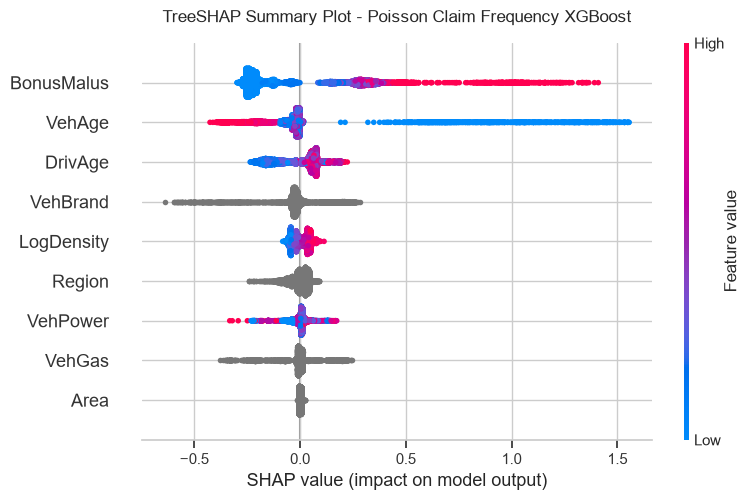

In [3]:
explainer = TreeSHAPExplainer(freq_xgb.booster)
explanation = explainer.compute_shap_values(test_eval, sample_size=10000, random_state=42)
imp_df = explainer.get_feature_importance_df()

display(imp_df)

plt.figure(figsize=(10, 6))
shap.summary_plot(explanation, explainer.feature_data, show=False)
plt.title("TreeSHAP Summary Plot - Poisson Claim Frequency XGBoost", fontsize=12, pad=15)
plt.tight_layout()
plt.show()

## 3. Partial Dependence & Non-Linear Risk Curves

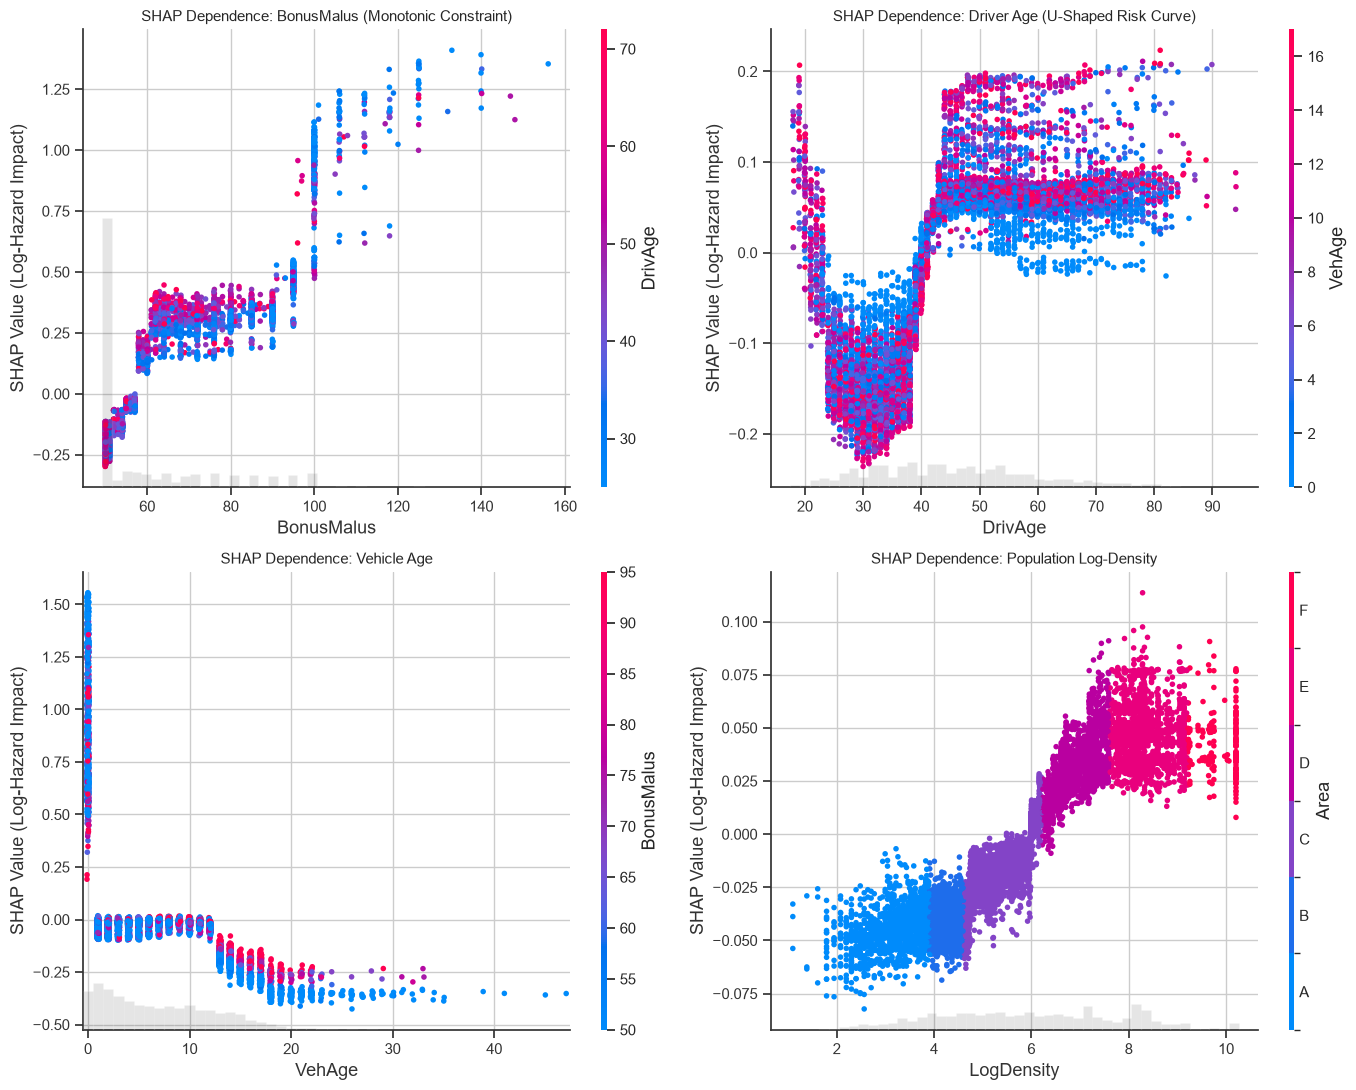

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# BonusMalus
plt.sca(axes[0, 0])
shap.plots.scatter(explanation[:, "BonusMalus"], color=explanation[:, "DrivAge"], ax=axes[0, 0], show=False)
axes[0, 0].set_title("SHAP Dependence: BonusMalus (Monotonic Constraint)", fontsize=11)
axes[0, 0].set_ylabel("SHAP Value (Log-Hazard Impact)")

# Driver Age
plt.sca(axes[0, 1])
shap.plots.scatter(explanation[:, "DrivAge"], color=explanation[:, "VehAge"], ax=axes[0, 1], show=False)
axes[0, 1].set_title("SHAP Dependence: Driver Age (U-Shaped Risk Curve)", fontsize=11)
axes[0, 1].set_ylabel("SHAP Value (Log-Hazard Impact)")

# Vehicle Age
plt.sca(axes[1, 0])
shap.plots.scatter(explanation[:, "VehAge"], color=explanation[:, "BonusMalus"], ax=axes[1, 0], show=False)
axes[1, 0].set_title("SHAP Dependence: Vehicle Age", fontsize=11)
axes[1, 0].set_ylabel("SHAP Value (Log-Hazard Impact)")

# Territorial Log-Density
plt.sca(axes[1, 1])
shap.plots.scatter(explanation[:, "LogDensity"], color=explanation[:, "Area"], ax=axes[1, 1], show=False)
axes[1, 1].set_title("SHAP Dependence: Population Log-Density", fontsize=11)
axes[1, 1].set_ylabel("SHAP Value (Log-Hazard Impact)")

plt.tight_layout()
plt.show()

## 4. Tariff Relativities: GLM vs XGBoost Ratebooks

Comparison of exposure-weighted marginal relativities across demographic, vehicle, bonus-malus, and territorial segments.

In [5]:
test_eval["DrivAge_Band"] = pd.cut(
    test_eval["DrivAge"],
    bins=[17, 25, 35, 50, 65, 100],
    labels=["18-25", "26-35", "36-50", "51-65", "66+"]
)
test_eval["VehAge_Band"] = pd.cut(
    test_eval["VehAge"],
    bins=[-1, 0, 4, 9, 14, 100],
    labels=["0 (New)", "1-4", "5-9", "10-14", "15+"]
)
test_eval["BonusMalus_Band"] = pd.cut(
    test_eval["BonusMalus"],
    bins=[49, 50, 65, 80, 100, 150, 350],
    labels=["50 (Max Bonus)", "51-65", "66-80", "81-100 (Base)", "101-150", ">150 (Severe Malus)"]
)

rel_age = build_binned_relativities(test_eval, "PurePremium_GLM", "PurePremium_XGB", "DrivAge_Band")
rel_veh = build_binned_relativities(test_eval, "PurePremium_GLM", "PurePremium_XGB", "VehAge_Band")
rel_bm = build_binned_relativities(test_eval, "PurePremium_GLM", "PurePremium_XGB", "BonusMalus_Band")
rel_area = build_binned_relativities(test_eval, "PurePremium_GLM", "PurePremium_XGB", "Area")

print("--- Driver Age Relativities ---")
display(rel_age[["DrivAge_Band", "Policies", "Exposure_Pct", "GLM_Relativity", "XGB_Relativity"]])

print("--- Bonus-Malus Relativities ---")
display(rel_bm[["BonusMalus_Band", "Policies", "Exposure_Pct", "GLM_Relativity", "XGB_Relativity"]])

--- Driver Age Relativities ---


,DrivAge_Band,Policies,Exposure_Pct,GLM_Relativity,XGB_Relativity
0,18-25,7863,4.570622,1.829857,1.758036
1,26-35,29917,19.308451,0.984158,1.024655
2,36-50,50376,36.947947,0.941227,0.945200
3,51-65,34116,26.871332,0.998085,0.960621
4,66+,13331,12.301648,0.897242,0.930266


--- Bonus-Malus Relativities ---


,BonusMalus_Band,Policies,Exposure_Pct,GLM_Relativity,XGB_Relativity
0,50 (Max Bonus),76865,62.881397,0.816216,0.806161
1,51-65,25209,17.661998,0.876827,1.023029
2,66-80,17355,10.490667,1.251310,1.315693
3,81-100 (Base),14650,7.987858,2.009427,1.770033
4,101-150,1489,0.954786,3.826773,3.356984
5,>150 (Severe Malus),35,0.023292,15.320083,3.961352


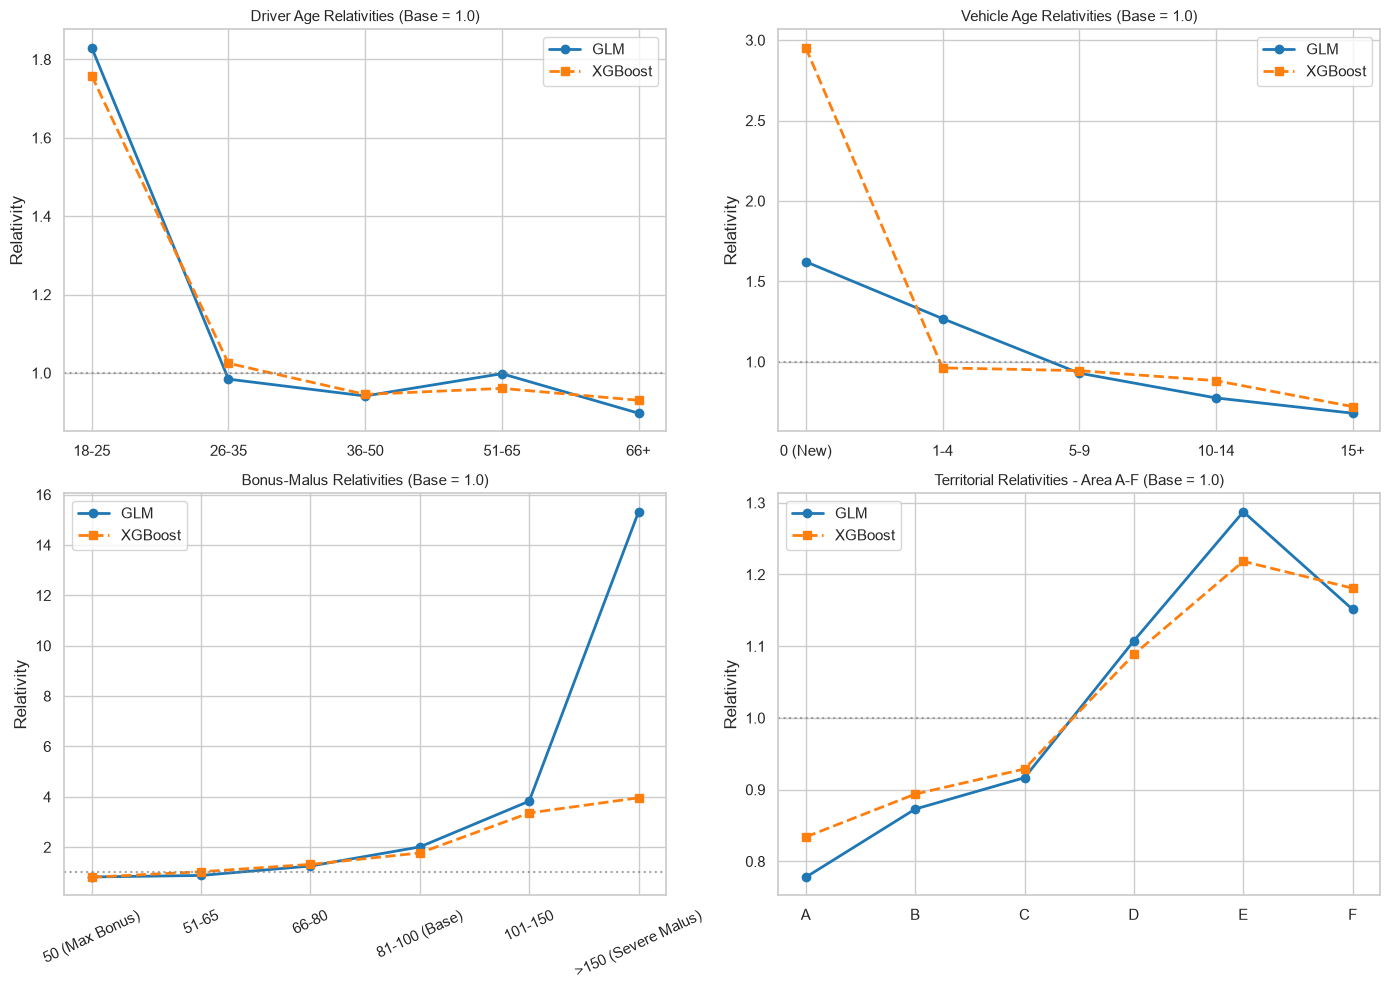

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Driver Age
axes[0, 0].plot(rel_age["DrivAge_Band"], rel_age["GLM_Relativity"], marker="o", label="GLM", color="#1f77b4", lw=2)
axes[0, 0].plot(rel_age["DrivAge_Band"], rel_age["XGB_Relativity"], marker="s", label="XGBoost", color="#ff7f0e", lw=2, linestyle="--")
axes[0, 0].axhline(1.0, color="grey", linestyle=":", alpha=0.7)
axes[0, 0].set_title("Driver Age Relativities (Base = 1.0)", fontsize=11)
axes[0, 0].set_ylabel("Relativity")
axes[0, 0].legend()

# Vehicle Age
axes[0, 1].plot(rel_veh["VehAge_Band"], rel_veh["GLM_Relativity"], marker="o", label="GLM", color="#1f77b4", lw=2)
axes[0, 1].plot(rel_veh["VehAge_Band"], rel_veh["XGB_Relativity"], marker="s", label="XGBoost", color="#ff7f0e", lw=2, linestyle="--")
axes[0, 1].axhline(1.0, color="grey", linestyle=":", alpha=0.7)
axes[0, 1].set_title("Vehicle Age Relativities (Base = 1.0)", fontsize=11)
axes[0, 1].set_ylabel("Relativity")
axes[0, 1].legend()

# Bonus-Malus
axes[1, 0].plot(rel_bm["BonusMalus_Band"], rel_bm["GLM_Relativity"], marker="o", label="GLM", color="#1f77b4", lw=2)
axes[1, 0].plot(rel_bm["BonusMalus_Band"], rel_bm["XGB_Relativity"], marker="s", label="XGBoost", color="#ff7f0e", lw=2, linestyle="--")
axes[1, 0].axhline(1.0, color="grey", linestyle=":", alpha=0.7)
axes[1, 0].set_title("Bonus-Malus Relativities (Base = 1.0)", fontsize=11)
axes[1, 0].set_ylabel("Relativity")
axes[1, 0].tick_params(axis="x", rotation=25)
axes[1, 0].legend()

# Geographic Area
axes[1, 1].plot(rel_area["Area"], rel_area["GLM_Relativity"], marker="o", label="GLM", color="#1f77b4", lw=2)
axes[1, 1].plot(rel_area["Area"], rel_area["XGB_Relativity"], marker="s", label="XGBoost", color="#ff7f0e", lw=2, linestyle="--")
axes[1, 1].axhline(1.0, color="grey", linestyle=":", alpha=0.7)
axes[1, 1].set_title("Territorial Relativities - Area A-F (Base = 1.0)", fontsize=11)
axes[1, 1].set_ylabel("Relativity")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## 5. Local Policyholder Quote Decompositions


ID: 1197694 | Age: 19 | VehAge: 7 | BM: 95 | Area: E
Pred Freq: XGB = 0.1953 / GLM = 0.2725 | Pure Premium: XGB = €347.98 / GLM = €497.87


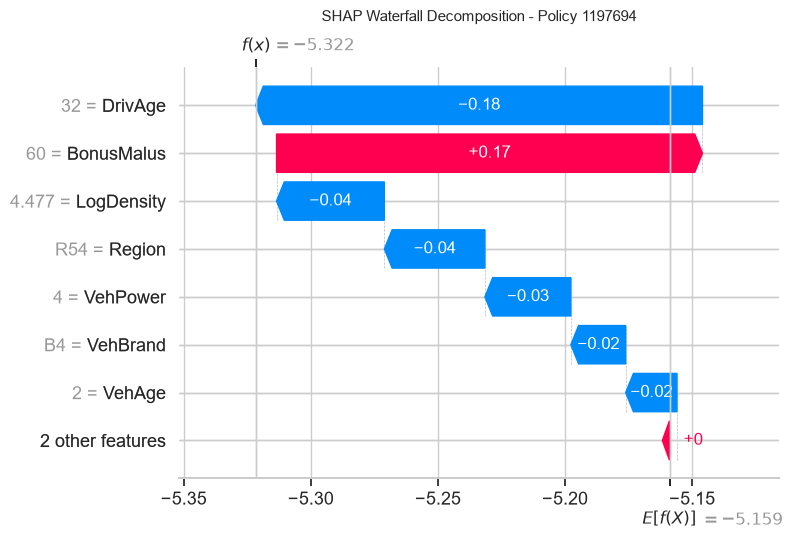


ID: 2001100 | Age: 60 | VehAge: 2 | BM: 50 | Area: F
Pred Freq: XGB = 0.0813 / GLM = 0.1296 | Pure Premium: XGB = €113.17 / GLM = €168.91


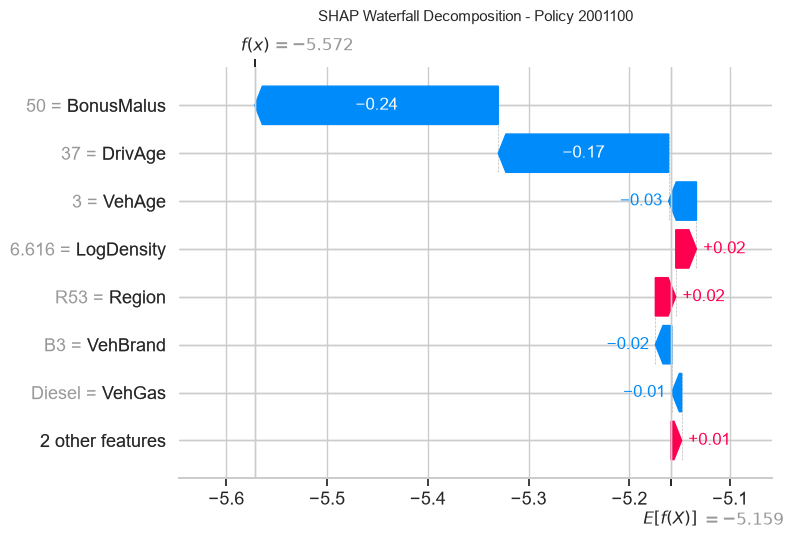


ID: 1180128 | Age: 51 | VehAge: 3 | BM: 50 | Area: C
Pred Freq: XGB = 0.0875 / GLM = 0.0964 | Pure Premium: XGB = €143.67 / GLM = €161.70


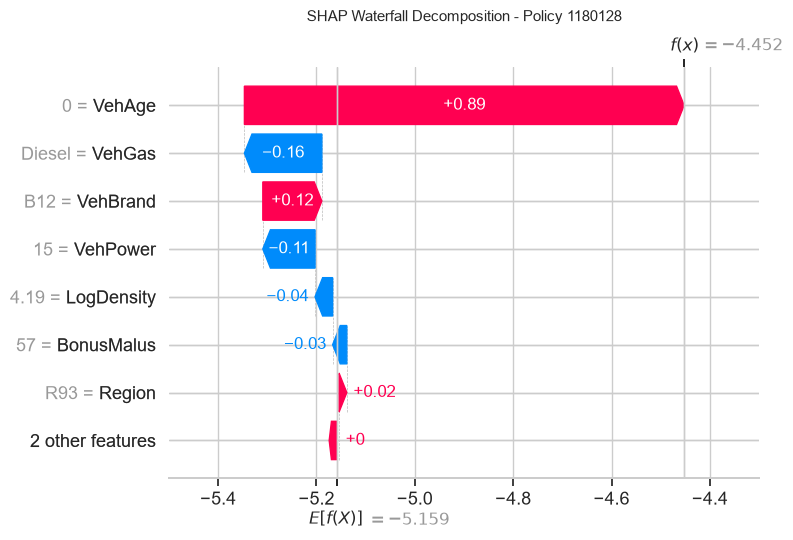

In [7]:
sample_indices = [0, 42, 108]

for idx in sample_indices:
    policy = test_eval.iloc[idx]
    sh_val = explanation[idx]
    
    print(f"\nID: {policy['IDpol']} | Age: {policy['DrivAge']} | VehAge: {policy['VehAge']} | BM: {policy['BonusMalus']} | Area: {policy['Area']}")
    print(f"Pred Freq: XGB = {policy['Pred_Freq_XGB']:.4f} / GLM = {policy['Pred_Freq_GLM']:.4f} | Pure Premium: XGB = €{policy['PurePremium_XGB']:.2f} / GLM = €{policy['PurePremium_GLM']:.2f}")
    
    plt.figure(figsize=(9, 4))
    shap.plots.waterfall(sh_val, max_display=8, show=False)
    plt.title(f"SHAP Waterfall Decomposition - Policy {policy['IDpol']}", fontsize=11, pad=12)
    plt.tight_layout()
    plt.show()